# check_export (dask)

Reduced statistics of the A1 dataset, computed **lazily with dask** so the full
(3001, 5, 128, 129, 128) field is never loaded into RAM.

Quantities (all reductions — no full field kept):
1. Mean velocity profile along y           → (3, 129)
2. Mean & std of velocity over time        → (3, 128, 129, 128)   [for train/test uniformity]
3. Stationarity over time (d⟨u⟩/dt)        → (3, 129) per snapshot → profile
4. Friction Re over time                   → (N,)
5. Divergence through time (mean div u)    → (N,)

Dask handles parallelism (64 threads) and memory; we just declare the reductions.

In [13]:
import zarr
import s3fs
import numpy as np
import dask
import dask.array as da
from dask import delayed
import matplotlib.pyplot as plt
from tqdm.dask import TqdmCallback

# ---- config ----
S3_BUCKET = "simulations"
STORE_PATH = "flow_export/A1"
ENDPOINT = "http://localhost:8333"          # SeaweedFS
N_WORKERS = 32

Lx, Nx = 12.57, 128
Ly, Ny = 2.0, 129
Lz, Nz = 4.19, 128
nu = 1/4763

fs = s3fs.S3FileSystem(profile='default', client_kwargs={'endpoint_url': ENDPOINT})

# channel (small, load directly)
def _charr(name):
    return np.asarray(zarr.open_array(
        store=s3fs.S3Map(root=f"{S3_BUCKET}/{STORE_PATH}/channel.zarr/{name}", s3=fs), mode="r"))
x, y, z = _charr('x'), _charr('y'), _charr('z')

# lazy dask array over the full dataset (nothing loaded yet)
# chunk by 64 snapshots: ~50 input blocks -> ~550 reduction tasks (vs 35k with chunk=1).
# Each block is ~2.7 GB, held briefly; dask keeps only a few live at once.
CHUNK_TIME = 64
zarr_data = zarr.open_array(store=s3fs.S3Map(root=f"{S3_BUCKET}/{STORE_PATH}/data.zarr", s3=fs), mode="r")
data = da.from_array(zarr_data, chunks=(CHUNK_TIME, 1, 128, 129, 128))
u = zarr_data[:, :3]  # Load everything so its faster                                                # (N, 3, X, Y, Z) lazy
print("data:", data.shape, data.dtype, "| time-blocks:", len(data.chunks[0]))
# print("Chunk size:", u.chunksize)
# print("Number of chunks:", u.npartitions)
# print("Chunk layout:", u.numblocks)

data: (3001, 5, 128, 129, 128) float32 | time-blocks: 47


In [15]:
print(f"{u.nbytes / 1024**3:.2f} GiB")

70.89 GiB


## 1. Mean velocity profile along y

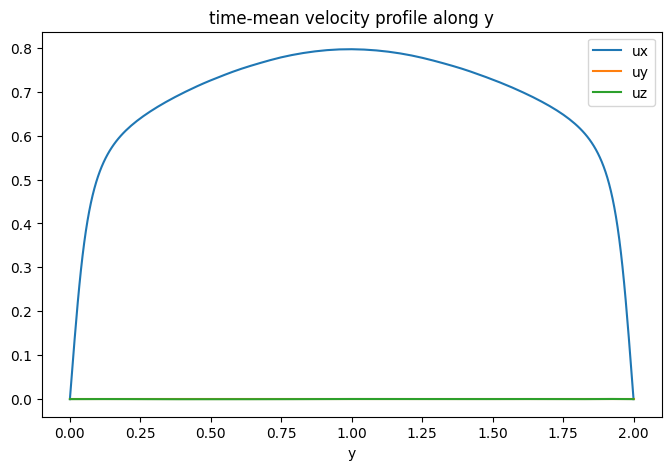

(3, 129)

In [3]:
with TqdmCallback(desc="u mean"):
    u_mean_y = u.mean(axis=(0, 2, 4))      # (3, 129)
plt.figure(figsize=(8, 5))
for c, lab in enumerate(['ux', 'uy', 'uz']):
    plt.plot(y, u_mean_y[c], label=lab)
plt.title('time-mean velocity profile along y'); plt.xlabel('y'); plt.legend(); plt.show()
u_mean_y.shape

## 2. Mean & std of velocity per sample, per component (for train/test uniformity)

Mean and std over the **spatial** axes (x,y,z) for each snapshot and each velocity component
giving `(N, 3)`. Lets you check that the per-sample statistics are uniform over time before
splitting train/test.

mean-per-sample: (3001, 3)  std-per-sample: (3001, 3)
ux: mean-of-mean=0.5721  std-of-mean=0.0173  | mean-of-std=0.2115  std-of-std=0.0166
uy: mean-of-mean=-0.0000  std-of-mean=0.0000  | mean-of-std=0.0287  std-of-std=0.0041
uz: mean-of-mean=0.0000  std-of-mean=0.0006  | mean-of-std=0.0398  std-of-std=0.0057


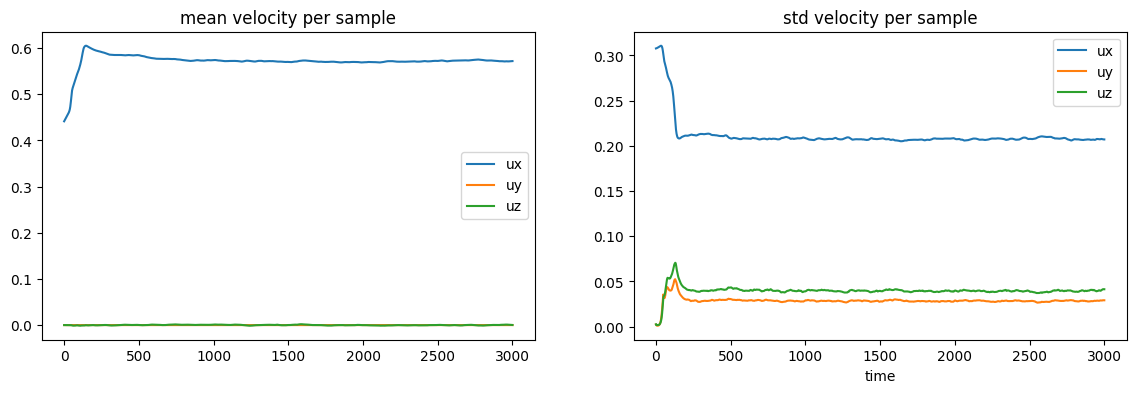

In [4]:
with TqdmCallback(desc='mean-per-sample'):
    u_mean_s = u.mean(axis=(2, 3, 4))      # (N, 3) - mean over x,y,z per snapshot
with TqdmCallback(desc='std-per-sample'):
    u_std_s  = u.std(axis=(2, 3, 4))       # (N, 3) - std over x,y,z per snapshot
print('mean-per-sample:', u_mean_s.shape, ' std-per-sample:', u_std_s.shape)

# uniformity: do the per-sample stats stay flat over time? (per component)
for c, lab in enumerate(['ux', 'uy', 'uz']):
    print(f"{lab}: mean-of-mean={u_mean_s[:, c].mean():.4f}  std-of-mean={u_mean_s[:, c].std():.4f}  "
          f"| mean-of-std={u_std_s[:, c].mean():.4f}  std-of-std={u_std_s[:, c].std():.4f}")

# per-sample mean & std over time (per component)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for c, lab in enumerate(['ux', 'uy', 'uz']):
    ax[0].plot(u_mean_s[:, c], label=lab)
    ax[1].plot(u_std_s[:, c], label=lab)
ax[0].set_title('mean velocity per sample'); ax[0].legend()
ax[1].set_title('std velocity per sample'); ax[1].legend()
plt.xlabel('time'); plt.show()

## 3. Stationarity over time  (d⟨u⟩/dt of the y-profile)

dudt: (3001, 3, 129)


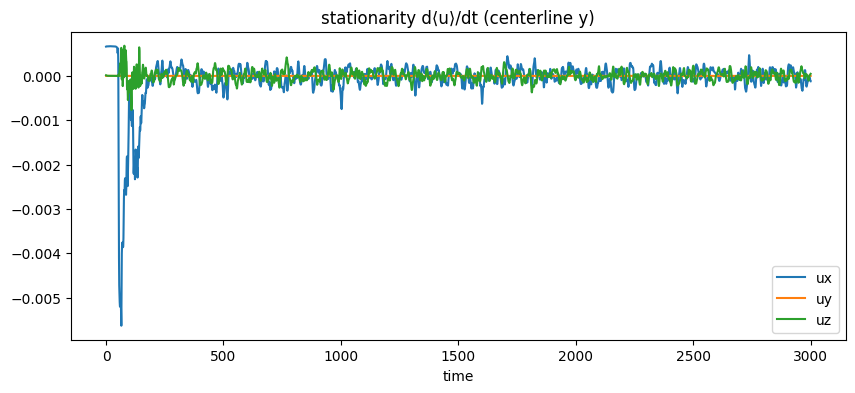

In [8]:
# per-snapshot y-profile (mean over x,z) -> (N, 3, 129), then d/dt
with TqdmCallback(desc='u-prof'):
    u_prof = u.mean(axis=(2, 4))           # (N, 3, 129)
dudt = np.gradient(u_prof, axis=0)               # (N, 3, 129)
print("dudt:", dudt.shape)
plt.figure(figsize=(10, 4))
for c, lab in enumerate(['ux', 'uy', 'uz']):
    plt.plot(dudt[:, c, 64], label=lab)          # centerline y
plt.title('stationarity d⟨u⟩/dt (centerline y)'); plt.xlabel('time'); plt.legend(); plt.show()

## 4. Friction Re over time

From the wall-normal velocity gradient `du/dy|_wall` (simple finite difference, as in the
original notebook). Per-snapshot, streamwise component.

mean friction Re: 2649.119805605182   mean u_tau: 0.5561872361127822


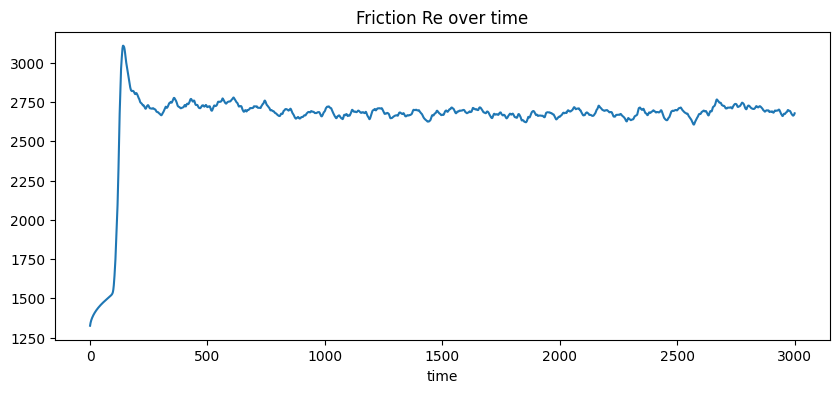

In [5]:
def u_tau_of_profile(um):              # um: (129,) streamwise mean profile
    g_wall = np.gradient(um, y)[0]    # du/dy at y=0
    return np.sqrt(nu * g_wall / (y[1] - y[0]))

# per-snapshot streamwise profile (N, 129)
with TqdmCallback(desc='ux-prof'):
    ux_prof = u[:, 0].mean(axis=(1, 3))   # mean over x,z -> (N, 129)
u_tau = np.array([u_tau_of_profile(ux_prof[t]) for t in range(ux_prof.shape[0])])
re_t = u_tau / nu
print("mean friction Re:", float(re_t.mean()), "  mean u_tau:", float(u_tau.mean()))
plt.figure(figsize=(10, 4)); plt.plot(re_t); plt.title('Friction Re over time'); plt.xlabel('time'); plt.show()

## 5. Divergence through time  (mean of div·u per snapshot)

`div·u = ∂ux/∂x + ∂uy/∂y + ∂uz/∂z`, derivatives via FFT (periodic in x,z) and a simple
gradient in y. One scalar per snapshot. Should be ~0 for incompressible flow.

divergence:   0%|          | 0/3001 [00:00<?, ?it/s]

div_t: (3001,) mean: 2.158098404394406e-22 max|div|: 9.54770285227545e-19


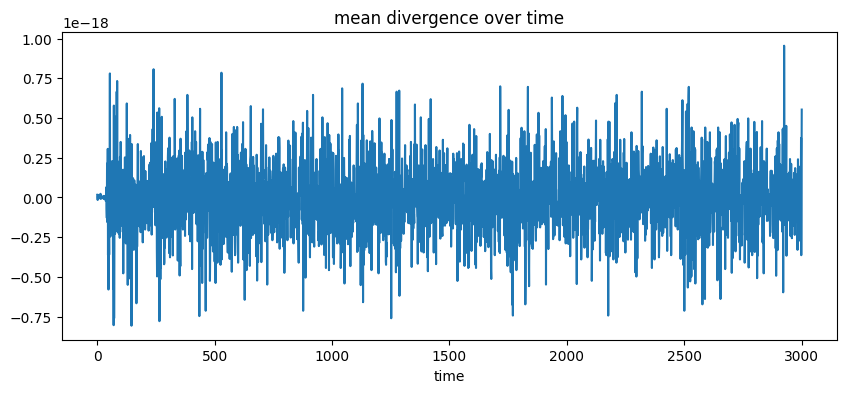

In [6]:
def div_one(t):                         # t: snapshot index -> scalar mean divergence
    # open a fresh S3 handle per call so nothing non-picklable is captured
    import zarr as _zarr, s3fs as _s3fs
    _fs = _s3fs.S3FileSystem(profile='default', client_kwargs={'endpoint_url': ENDPOINT})
    _za = _zarr.open_array(store=_s3fs.S3Map(root=f"{S3_BUCKET}/{STORE_PATH}/data.zarr", s3=_fs), mode='r')
    u_snap = np.array(_za[t, :3])
    def dfft(f, axis, h):
        n = f.shape[axis]
        k = 2*np.pi*np.fft.fftfreq(n, d=h)
        shape = [1]*f.ndim; shape[axis] = n
        kb = np.broadcast_to(k.reshape(shape), f.shape)
        return np.fft.ifftn(1j*kb*np.fft.fftn(f, axes=(axis,)), axes=(axis,)).real
    dux = dfft(u_snap[0], 0, Lx/Nx)
    dvy = dfft(u_snap[1], 1, Ly/(Ny-1))
    dwz = dfft(u_snap[2], 2, Lz/Nz)
    return float((dux + dvy + dwz).mean())

N = data.shape[0]
tasks = [delayed(div_one)(int(t)) for t in range(N)]
with TqdmCallback(desc='divergence'):
    div_t = np.array(dask.compute(*tasks))      # (N,) - one dask compute
print("div_t:", div_t.shape, "mean:", float(div_t.mean()), "max|div|:", float(np.abs(div_t).max()))
plt.figure(figsize=(10, 4)); plt.plot(div_t); plt.title('mean divergence over time'); plt.xlabel('time'); plt.show()

In [ ]:
# no client to close (threads scheduler)